# Read accounting: what happens to every sequenced read

Reads were decoded without adapter trimming. When the insert (UMI + barcode) is shorter than 47 nt, Read 1 runs into the Read 2 handle (`CTGTCTCTTATAC...`). The position of the handle in Read 1 gives the insert length (detectable up to 34 nt, because a 13-nt match is required).

Classes:
* insert ≤ 10 nt: no barcode at all (UMI or less);
* 11-25 nt: at most 15 nt of barcode;
* 26-34 nt: 16-24 nt of barcode;
* full length: handle not found in Read 1, insert ≥ 35 nt (≥ 25 nt of barcode).

Probes were synthesized 5' to 3' and the Read 2 handle is added last, so a chain that stopped early cannot be amplified. Short inserts therefore come from molecules with internal deletions, or from primer and adapter artefacts.

In [1]:
import numpy as np
import pandas as pd

from common import ARRAYS, COLORS, OUT, THRESHOLDS, UMI_LEN, BC_LEN, load_raw, load_assignments, load_layout, setup_matplotlib

plt = setup_matplotlib()
raw = {name: load_raw(name) for name in ARRAYS}

## Insert-length classes

In [2]:
def insert_class(L):
    return np.select([L < 0, L <= 10, L <= 25, L <= 34], ["full length", "≤ 10 nt", "11-25 nt", "26-34 nt"], "full length")


CLASSES = ["≤ 10 nt", "11-25 nt", "26-34 nt", "full length"]
classes = pd.DataFrame({name: pd.Series(insert_class(df.insert_len.values)).value_counts(normalize=True)
                        for name, df in raw.items()}).reindex(CLASSES) * 100
classes.loc["reads"] = [len(df) for df in raw.values()]
classes.round(2).to_csv(OUT / "insert_classes.csv")
classes.round(2)

,Dual barcodes,Greedy + 2-OPT,Zipcodes
≤ 10 nt,11.37,12.36,6.93
11-25 nt,17.03,19.12,12.99
26-34 nt,7.46,7.95,6.63
full length,64.13,60.57,73.45
reads,372835.00,306222.00,395770.00


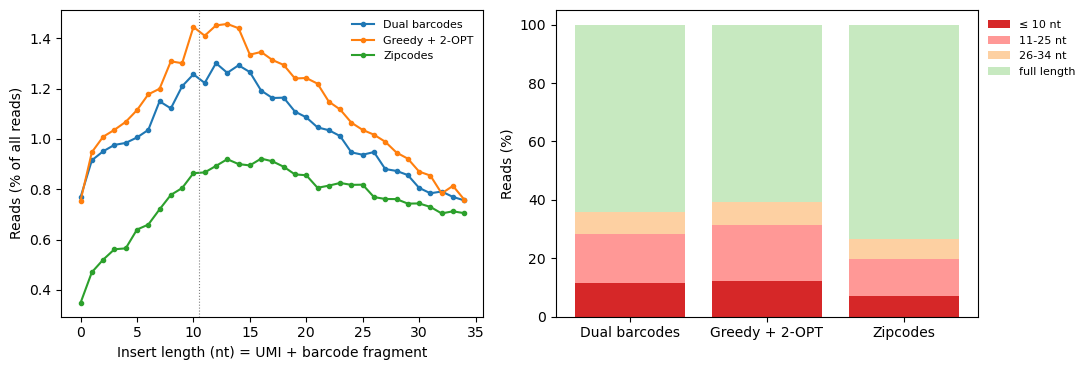

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, df in raw.items():
    L = df.insert_len[df.insert_len >= 0]
    counts = L.value_counts().reindex(range(0, 35), fill_value=0) / len(df) * 100
    axes[0].plot(counts.index, counts.values, "o-", ms=3, color=COLORS[name], label=name)
axes[0].axvline(UMI_LEN + 0.5, color="grey", ls=":", lw=0.8)
axes[0].set_xlabel("Insert length (nt) = UMI + barcode fragment")
axes[0].set_ylabel("Reads (% of all reads)")
axes[0].legend(frameon=False, fontsize=8)
bottom = np.zeros(len(ARRAYS))
for cls, color in zip(CLASSES, ["#d62728", "#ff9896", "#fdd0a2", "#c7e9c0"]):
    vals = classes.loc[cls, list(ARRAYS)].values
    axes[1].bar(range(len(ARRAYS)), vals, bottom=bottom, color=color, label=cls)
    bottom += vals
axes[1].set_xticks(range(len(ARRAYS)), list(ARRAYS))
axes[1].set_ylabel("Reads (%)")
axes[1].legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1), loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "insert_length.pdf")
plt.show()

## What is in the shortest inserts?

An insert of 0 nt means Read 1 starts directly with the Read 2 handle: the Read 1 handle was ligated or primed directly onto the Read 2 handle (primer or adapter dimer, or a probe that lost the whole UMI and barcode). Inserts of 1-10 nt contain only part of a UMI.

In [4]:
short = {name: df.insert_len[(df.insert_len >= 0) & (df.insert_len <= 10)].value_counts().sort_index()
         for name, df in raw.items()}
pd.DataFrame(short).fillna(0).astype(int).T

insert_len,0,1,2,3,4,5,6,7,8,9,10
Dual barcodes,2866,3412,3545,3640,3669,3750,3862,4286,4181,4509,4686
Greedy + 2-OPT,2312,2901,3089,3173,3270,3413,3605,3673,4007,3984,4425
Zipcodes,1380,1861,2058,2222,2236,2532,2610,2850,3077,3185,3419


## Assignment rate over all reads and over full-length reads

Both numerator and denominator are restricted to full-length reads for the second rate. Reads assigned to real barcodes that have a short insert are counted separately.

In [5]:
rows = []
for name in ARRAYS:
    df = raw[name]
    full_ids = set(df.read_id[df.full_length])
    for r in THRESHOLDS:
        asg = load_assignments(name, r)
        asg["full_length"] = asg.read_id.isin(full_ids)
        n_all, n_full = len(df), len(full_ids)
        real = asg[asg.is_real]
        rows.append({
            "layout": name, "threshold": r, "reads": n_all, "full_length_reads": n_full,
            "assigned_real": len(real), "assigned_real_full_length": int(real.full_length.sum()),
            "assigned_real_short_insert": int((~real.full_length).sum()),
            "assignment_rate_all (%)": 100 * len(real) / n_all,
            "assignment_rate_full_length (%)": 100 * real.full_length.sum() / n_full,
            "decoy_fraction_full_length (%)": 100 * (~asg[asg.full_length].is_real).mean(),
            "decoy_fraction_short_insert (%)": 100 * (~asg[~asg.full_length].is_real).mean(),
            "short_insert_assigned_any": int((~asg.full_length).sum()),
        })
rates = pd.DataFrame(rows).set_index(["layout", "threshold"])
rates.round(3).to_csv(OUT / "assignment_rates_full_length.csv")
rates.round(2)

reads  full_length_reads  assigned_real  \
layout         threshold                                             
Dual barcodes  5          372835             239095         128421   
               6          372835             239095         156918   
               7          372835             239095         176612   
Greedy + 2-OPT 5          306222             185479          38275   
               6          306222             185479          53611   
               7          306222             185479          66326   
Zipcodes       5          395770             290691         115111   
               6          395770             290691         151957   
               7          395770             290691         179600   

                          assigned_real_full_length  \
layout         threshold                              
Dual barcodes  5                             128050   
               6                             155510   
               7                             173416   
Greedy + 2-OPT 5                              38267   
               6                              53568   
               7                              66018   
Zipcodes       5                             114901   
               6                             151248   
               7                             177964   

                          assigned_real_short_insert  assignment_rate_all (%)  \
layout         threshold                                                        
Dual barcodes  5                                 371                    34.44   
               6                                1408                    42.09   
               7                                3196                    47.37   
Greedy + 2-OPT 5                                   8                    12.50   
               6                                  43                    17.51   
               7                                 308                    21.66   
Zipcodes       5                                 210                    29.09   
               6                                 709                    38.40   
               7                                1636                    45.38   

                          assignment_rate_full_length (%)  \
layout         threshold                                    
Dual barcodes  5                                    53.56   
               6                                    65.04   
               7                                    72.53   
Greedy + 2-OPT 5                                    20.63   
               6                                    28.88   
               7                                    35.59   
Zipcodes       5                                    39.53   
               6                                    52.03   
               7                                    61.22   

                          decoy_fraction_full_length (%)  \
layout         threshold                                   
Dual barcodes  5                                    1.26   
               6                                    2.86   
               7                                    4.23   
Greedy + 2-OPT 5                                    0.00   
               6                                    0.02   
               7                                    0.28   
Zipcodes       5                                    1.18   
               6                                    2.51   
               7                                    3.99   

                          decoy_fraction_short_insert (%)  \
layout         threshold                                    
Dual barcodes  5                                    22.38   
               6                                    27.50   
               7                                    29.40   
Greedy + 2-OPT 5                                     0.00   
               6                                     6.52  

The decoy fraction among assigned short-insert reads, compared with full-length reads, shows whether these assignments are mostly false. With a global decoy share of 1/3, a decoy fraction of $d$ among assigned reads corresponds to an estimated precision of $1 - 3d$ (Dual, Greedy) or $1 - d/\phi_{\text{eff}}$ (Zipcodes).

In [6]:
calib = pd.read_csv(OUT.parents[1] / "precision_calibration" / "precision_calibration_1M.csv",
                    index_col=["layout", "threshold"])
prec = pd.DataFrame({
    "precision_full_length (%)": 100 * (1 - rates["decoy_fraction_full_length (%)"] / 100 / calib.phi_eff.reindex(rates.index)),
    "precision_short_insert (%)": 100 * (1 - rates["decoy_fraction_short_insert (%)"] / 100 / calib.phi_eff.reindex(rates.index)),
    "short-insert reads assigned": rates.short_insert_assigned_any,
})
prec.round(2).to_csv(OUT / "precision_by_insert_class.csv")
prec.round(2)

precision_full_length (%)  \
layout         threshold                              
Dual barcodes  5                              96.19   
               6                              91.72   
               7                              87.42   
Greedy + 2-OPT 5                             100.00   
               6                              99.93   
               7                              99.20   
Zipcodes       5                              93.79   
               6                              86.66   
               7                              79.17   

                          precision_short_insert (%)  \
layout         threshold                               
Dual barcodes  5                               32.48   
               6                               20.42   
               7                               12.59   
Greedy + 2-OPT 5                              100.00   
               6                               80.20   
               7                               32.46   
Zipcodes       5                             -230.80   
               6                             -219.35   
               7                             -246.76   

                          short-insert reads assigned  
layout         threshold                               
Dual barcodes  5                                  478  
               6                                 1942  
               7                                 4527  
Greedy + 2-OPT 5                                    8  
               6                                   46  
               7                                  405  
Zipcodes       5                                  566  
               6                                 1782  
               7                                 4867

## Where do the barcode fragments of short inserts come from?

For inserts with at least 12 nt of barcode (insert 22-34 nt), the first and the last 12 nt of the fragment are compared exactly with the first and last 12 nt of all printed barcodes.
* prefix match: the fragment starts like a barcode, the rest is missing (deletion at the 3' end of the barcode, next to the Read 2 handle);
* suffix match: the fragment ends like a barcode (deletion at the 5' end, next to the UMI);
* both: the fragment joins the start and the end of barcodes (internal deletion);
* neither: errors in both ends or not barcode-derived.

The chance that a random 12-mer matches one of the 85,305 prefixes is about 85,305 / 4^12 ≈ 0.5%.

In [7]:
K = 12
rows = []
for name in ARRAYS:
    lay = load_layout(name)
    prefixes, suffixes = set(lay.barcode.str[:K]), set(lay.barcode.str[-K:])
    df = raw[name]
    sub = df[(df.insert_len >= UMI_LEN + K) & (df.insert_len <= 34)]
    frag = pd.Series([r1[UMI_LEN:L] for r1, L in zip(sub.r1, sub.insert_len)])
    pre = frag.str[:K].isin(prefixes)
    suf = frag.str[-K:].isin(suffixes)
    shuffled = frag.apply(lambda s: "".join(np.random.default_rng(len(s)).permutation(list(s))))
    rows.append({"layout": name, "fragments": len(frag),
                 "prefix only (%)": 100 * (pre & ~suf).mean(), "suffix only (%)": 100 * (~pre & suf).mean(),
                 "both (%)": 100 * (pre & suf).mean(), "neither (%)": 100 * (~pre & ~suf).mean(),
                 "shuffled control, prefix (%)": 100 * shuffled.str[:K].isin(prefixes).mean()})
fragments = pd.DataFrame(rows).set_index("layout")
fragments.round(2).to_csv(OUT / "short_insert_fragment_origin.csv")
fragments.round(2)

,fragments,prefix only (%),suffix only (%),both (%),neither (%),"shuffled control, prefix (%)"
layout,,,,,,
Dual barcodes,42477,10.62,3.60,0.15,85.62,0.04
Greedy + 2-OPT,37724,1.80,2.56,0.02,95.62,0.64
Zipcodes,39194,2.79,6.96,0.23,90.02,0.00


Fragment length of prefix-matching fragments: if deletions accumulate towards the end of the barcode (the last part synthesized before the Read 2 handle), prefix matches dominate at every length.

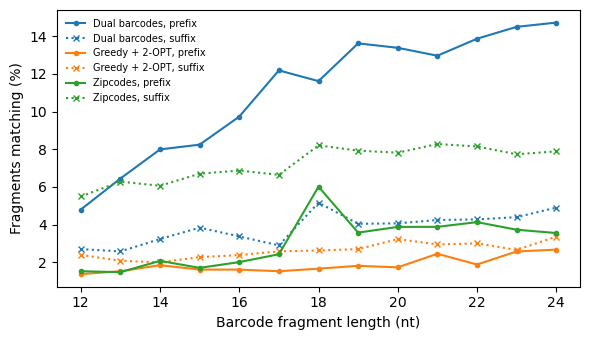

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in ARRAYS:
    lay = load_layout(name)
    prefixes, suffixes = set(lay.barcode.str[:K]), set(lay.barcode.str[-K:])
    df = raw[name]
    sub = df[(df.insert_len >= UMI_LEN + K) & (df.insert_len <= 34)]
    frag = pd.Series([r1[UMI_LEN:L] for r1, L in zip(sub.r1, sub.insert_len)])
    lengths = frag.str.len()
    share = pd.DataFrame({"L": lengths, "pre": frag.str[:K].isin(prefixes), "suf": frag.str[-K:].isin(suffixes)})
    g = share.groupby("L")[["pre", "suf"]].mean() * 100
    ax.plot(g.index, g.pre, "o-", ms=3, color=COLORS[name], label=f"{name}, prefix")
    ax.plot(g.index, g.suf, "x:", ms=4, color=COLORS[name], label=f"{name}, suffix")
ax.set_xlabel("Barcode fragment length (nt)")
ax.set_ylabel("Fragments matching (%)")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "short_insert_fragment_origin.pdf")
plt.show()